In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USE_COLAB = False
if USE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    local_path = "/content/drive/MyDrive"
else:
    local_path = os.path.join(os.getcwd(),"../","Numerical Results")

In [2]:
test_Box = pd.read_csv(f"{local_path}/RisultatiBoxPorzioniVeri/dimensioni_frattali.csv")
test_Rete = pd.read_csv(f"{local_path}/RisultatiRetePorzioni/dimensioni_frattali.csv")
test_No = pd.read_csv(f"{local_path}/RisultatiRetePorzioniNoAug/dimensioni_frattali.csv")

In [3]:
# Reference model: always predicts the mean fractal dimension of the training set.
# The generator (Dataset Creation/Fractal_Curves.ipynb) draws kappa ~ U(KAPPA_MIN, KAPPA_MAX)
# and sets D = 1 + kappa/8, so E[D] is available in closed form:
#     E[D] = 1 + E[kappa]/8 = 1 + (KAPPA_MIN + KAPPA_MAX)/2 / 8
# The training split (15k curves) has a sample mean within sigma_D/sqrt(15000) ~ 1e-3 of this,
# which shifts the errors below by < 0.1 percentage points.
KAPPA_MIN, KAPPA_MAX = 0.0, 3.5
D_TRAIN_MEAN = ((1 + KAPPA_MIN / 8) + (1 + KAPPA_MAX / 8) )/2
print(f"E[D] = {D_TRAIN_MEAN:.5f}")

D_MIN, D_MAX = 1 + KAPPA_MIN / 8, 1 + KAPPA_MAX / 8
# Mean relative error of the constant predictor, in percent. With D ~ U(D_MIN, D_MAX):
#   E[(E[D] - D)/D] = 1/(D_MAX - D_MIN) * Integral_{D_MIN}^{D_MAX} (E[D] - x)/x dx
#                   = ( E[D] * ln(D_MAX/D_MIN) - (D_MAX - D_MIN) ) / (D_MAX - D_MIN)
MEAN_ERR_REF = (D_TRAIN_MEAN * np.log(D_MAX / D_MIN) - (D_MAX - D_MIN)) / (D_MAX - D_MIN) * 100
print(f"mean relative error of the constant predictor: {MEAN_ERR_REF:+.3f}%")

E[D] = 1.21875
mean relative error of the constant predictor: +1.095%


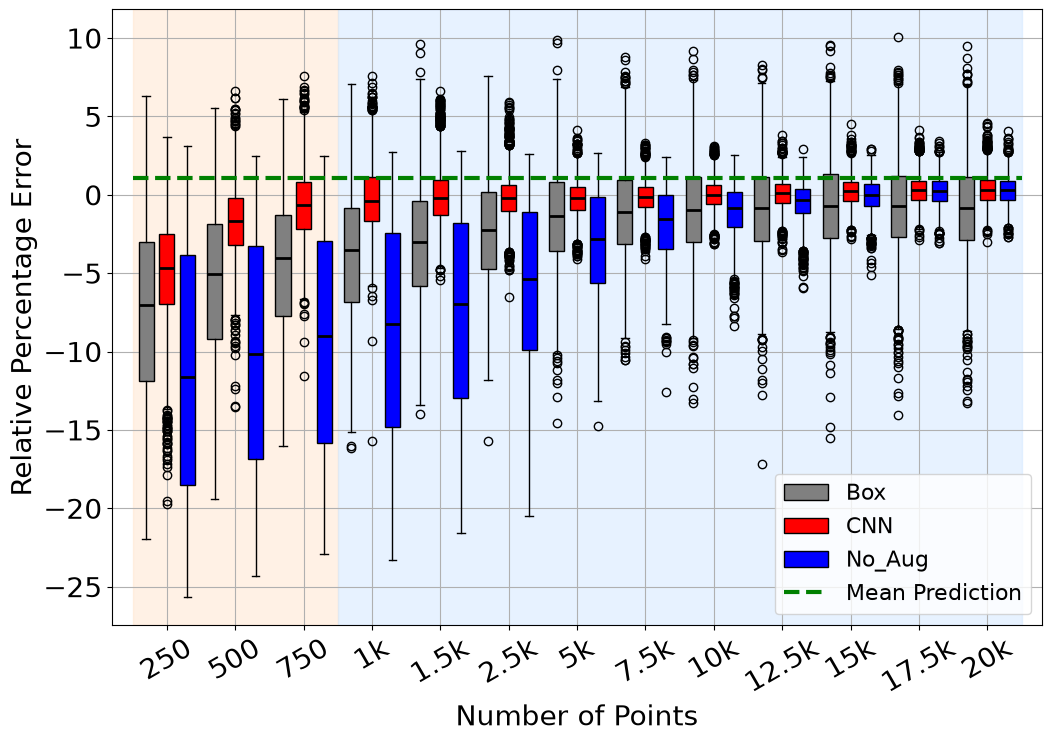

In [10]:
%matplotlib inline

porzione = ["250", "500", "750", "1k", "1.5k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k", "17.5k", "20k"]

cols = [f"Errore_{k}" for k in range(13)]

data_Box = [test_Box[col].dropna().values for col in cols]
data_Rete = [test_Rete[col].dropna().values for col in cols]
data_No = [test_No[col].dropna().values for col in cols]

soglia = 3

fig, ax = plt.subplots(figsize=(12, 8))

x = np.arange(1, 14)

offset = 0.3

bp1 = ax.boxplot(data_Box, positions=x - offset, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="grey"), medianprops=dict(color="black", linewidth=2))
bp2 = ax.boxplot(data_Rete, positions=x, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="red"), medianprops=dict(color="black", linewidth=2))
bp3 = ax.boxplot(data_No, positions=x + offset, widths=0.22,
                patch_artist=True, boxprops=dict(facecolor="blue"), medianprops=dict(color="black", linewidth=2))

ax.axvspan(0.5, soglia + 0.5, color="#ffe5cc", alpha=0.5)
ax.axvspan(soglia + 0.5, len(x) + 0.5, color="#d0e7ff", alpha=0.5)

# Reference: analytic mean relative error of the constant predictor D = E[D]
# (independent of the number of points, so drawn as a horizontal line).
x_lo, x_hi = x.min() - 0.5, x.max() + 0.5
line = ax.hlines(y=MEAN_ERR_REF, xmin=x_lo, xmax=x_hi, color="green", lw=3, ls="--")

ax.set_xticks(x)
ax.set_xticklabels(porzione, rotation=30)
ax.tick_params(axis='both', labelsize=20)


ax.set_xlabel("Number of Points", fontsize=20)
ax.set_ylabel("Relative Percentage Error", fontsize=20)
ax.grid(True)

ax.legend([bp1["boxes"][0], bp2["boxes"][0], bp3["boxes"][0], line],
          ["Box", "CNN", "No_Aug", "Mean Prediction"], loc="lower right", fontsize=16)

plt.show()


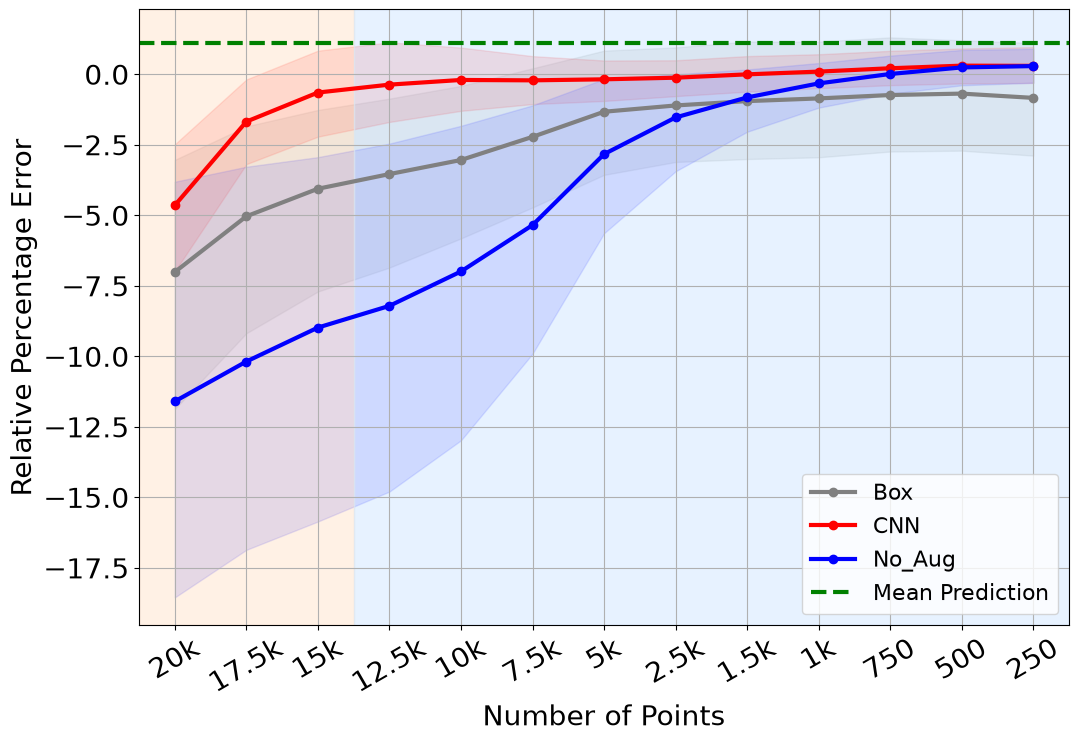

In [18]:
# Mean relative error vs number of points, with a shaded +/- 1 sigma band
fig, ax = plt.subplots(figsize=(12, 8))

x = np.arange(1, 14)

lines = []
for data, color, label in [(data_Box, "grey", "Box"),
                           (data_Rete, "red", "CNN"),
                           (data_No, "blue", "No_Aug")]:
    # mean = np.array([np.mean(d) for d in data])
    # std = np.array([0.5*d.std(ddof=1) for d in data])
    # l, = ax.plot(x, mean, color=color, lw=3, marker="o", label=label)
    # ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)
    median = np.array([np.median(d) for d in data])
    low_q = np.array([np.quantile(d,0.25) for d in data])
    high_q = np.array([np.quantile(d,0.75) for d in data])
    l, = ax.plot(x, median, color=color, lw=3, marker="o", label=label)
    ax.fill_between(x, low_q, high_q, color=color, alpha=0.2)
    lines.append(l)

ax.axvspan(0.5, soglia + 0.5, color="#ffe5cc", alpha=0.5)
ax.axvspan(soglia + 0.5, len(x) + 0.5, color="#d0e7ff", alpha=0.5)

# Reference: analytic mean relative error of the constant predictor D = E[D]
line = ax.hlines(y=MEAN_ERR_REF, xmin=x.min() - 0.5, xmax=x.max() + 0.5, color="green", lw=3, ls="--")

ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
ax.set_xticks(x)
ax.set_xticklabels(porzione, rotation=30)
ax.tick_params(axis='both', labelsize=20)

ax.set_xlabel("Number of Points", fontsize=20)
ax.set_ylabel("Relative Percentage Error", fontsize=20)
ax.grid(True)

ax.legend(lines + [line], ["Box", "CNN", "No_Aug", "Mean Prediction"], loc="lower right", fontsize=16)

plt.show()

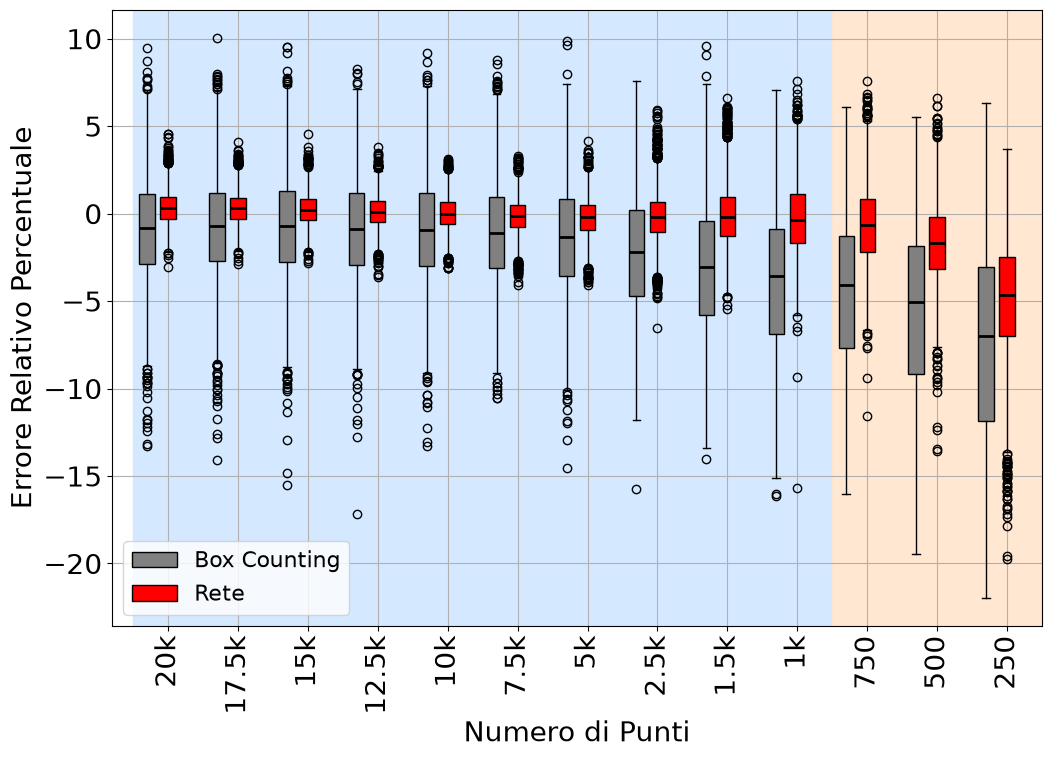

In [11]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

porzione = ["20k", "17.5k", "15k", "12.5k", "10k", "7.5k", "5k", "2.5k", "1.5k", "1k", "750", "500", "250"]

# posizioni invertite
x = np.arange(1, 14)[::-1]

# nuova soglia (invertita)
soglia_inv = 13 - soglia   # soglia = 3 → soglia_inv = 11

fig, ax = plt.subplots(figsize=(12, 8))

offset = 0.3

bp1 = ax.boxplot(data_Box, positions=x - offset, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="grey"), medianprops=dict(color="black", linewidth=2))
bp2 = ax.boxplot(data_Rete, positions=x, widths=0.22,
                 patch_artist=True, boxprops=dict(facecolor="red"), medianprops=dict(color="black", linewidth=2))
#bp3 = ax.boxplot(data_No, positions=x + offset, widths=0.22,
 #                patch_artist=True, boxprops=dict(facecolor="blue"), medianprops=dict(color="black", linewidth=2))

# sfondo aggiornato
ax.axvspan(0.5, soglia_inv + 0.5, color="#d0e7ff", alpha=0.9)
ax.axvspan(soglia_inv + 0.5, len(x) + 0.5, color="#ffe5cc", alpha=0.9)

ax.set_xticks(x)
#ax.set_xticklabels(porzione, fontsize=20)
ax.set_xticklabels(porzione[::-1], fontsize=20, rotation = 90)
plt.yticks(fontsize=20)

#ax.tick_params(axis='both', labelsize=10)

ax.set_xlabel("Numero di Punti", fontsize=20)
ax.set_ylabel("Errore Relativo Percentuale", fontsize=20)
ax.grid(True)

ax.legend([bp1["boxes"][0], bp2["boxes"][0]], # bp3["boxes"][0]],
          ["Box Counting", "Rete"], loc="lower left", fontsize=16)

plt.show()